# Advanced Image Classification with ImageNet

In this assignment, you will be asked to develop a convolutional neural network (CNN) to classify images from the CIFAR-100 dataset. At each step, you'll be guided through the process of developing a model architecture to solve a problem. Your goal is to create a CNN that attains at least 55% accuracy on the validation set.

### The CIFAR-100 Dataset

The [CIFAR-100 dataset](https://www.cs.toronto.edu/~kriz/cifar.html) consists of 60000 32x32 colour images in 100 classes, with 600 images per class. There are 50000 training images and 10000 test images. The dataset is divided into five training batches and one test batch, each with 10000 images. The test batch contains exactly 1000 randomly-selected images from each class. The training batches contain the remaining images in random order, but some training batches may contain more images from one class than another. Between them, the training batches contain exactly 500 images from each class.

### Tools

You will use Keras with TensorFlow to develop your CNN. For this assignment, it's strongly recommended that you use a GPU to accelerate your training, or else you might find it difficult to train your network in a reasonable amount of time. If you have a computer with a GPU that you wish to use, you can follow the [TensorFlow instructions](https://www.tensorflow.org/install/) for installing TensorFlow with GPU support. Otherwise, you can use [Google Colab](https://colab.research.google.com/) to complete this assignment. Colab provides free access to GPU-enabled machines. If you run into any issues, please contact us as soon as possible so that we can help you resolve them.

## Task 1: Data Exploration and Preprocessing (Complete or Incomplete)
### 1a: Load and Explore the Dataset
- Use the code below to download the dataset.
- Explore the dataset: examine the shape of the training and test sets, the dimensions of the images, and the number of classes. Show a few examples from the training set.

In [42]:
import tensorflow as tf

In [1]:
from keras.datasets import cifar100

# Load the CIFAR-100 dataset
(x_train, y_train), (x_test, y_test) = cifar100.load_data(label_mode='fine')

169001437/169001437 [==============================] - 16s 0us/step


In [2]:
class_names = [
    "apple", "aquarium_fish", "baby", "bear", "beaver", "bed", "bee", "beetle", "bicycle", "bottle",
    "bowl", "boy", "bridge", "bus", "butterfly", "camel", "can", "castle", "caterpillar", "cattle",
    "chair", "chimpanzee", "clock", "cloud", "cockroach", "couch", "crab", "crocodile", "cup", "dinosaur",
    "dolphin", "elephant", "flatfish", "forest", "fox", "girl", "hamster", "house", "kangaroo", "keyboard",
    "lamp", "lawn_mower", "leopard", "lion", "lizard", "lobster", "man", "maple_tree", "motorcycle", "mountain",
    "mouse", "mushroom", "oak_tree", "orange", "orchid", "otter", "palm_tree", "pear", "pickup_truck", "pine_tree",
    "plain", "plate", "poppy", "porcupine", "possum", "rabbit", "raccoon", "ray", "road", "rocket",
    "rose", "sea", "seal", "shark", "shrew", "skunk", "skyscraper", "snail", "snake", "spider",
    "squirrel", "streetcar", "sunflower", "sweet_pepper", "table", "tank", "telephone", "television", "tiger", "tractor",
    "train", "trout", "tulip", "turtle", "wardrobe", "whale", "willow_tree", "wolf", "woman", "worm"
]

In [3]:
# Your Code Here
x_train.shape
x_test.shape


(10000, 32, 32, 3)

In [4]:
image= x_train[0]
print("Shape of the image:", image.shape)

Shape of the image: (32, 32, 3)


In [5]:
print("Number of classes in CIFAR-100: ", len(set(y_train.flatten())))

Number of classes in CIFAR-100:  100


In [6]:
import numpy as np
import matplotlib.pyplot as plt

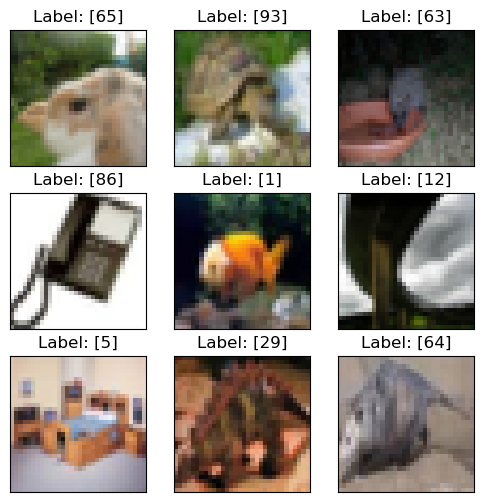

In [7]:
# Selecting 9 random indices
random_indices = np.random.choice(len(x_train), 9, replace=False)

# Creating a 3x3 grid plot
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[random_indices[i]], cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f"Label: {y_train[random_indices[i]]}")

    # Removing axis labels
    ax.set_xticks([])
    ax.set_yticks([])

plt.show()

### 1b: Data Preprocessing
- With the data downloaded, it's time to preprocess it. Start by normalizing the images so that they all have pixel values in the range [0, 1].
- Next, convert the labels to one-hot encoded vectors.
- Finally, split the training set into training and validation sets. Use 80% of the training set for training and the remaining 20% for validation.

In [8]:
# Your Code Here
# Normalize the images (scale pixel values to [0, 1])
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [9]:
# convert the labels to one-hot encoded vectors.
from keras.utils import to_categorical
y_train = to_categorical(y_train, num_classes=100)
y_test = to_categorical(y_test, num_classes=100)

In [10]:
#  split the training set into training and validation sets. Use 80% of the training set for training and the remaining 20% for validation.
from sklearn.model_selection import train_test_split
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2, random_state=42)

In [11]:
# Print the shapes to verify
print("Training data shape:", x_train.shape)
print("Validation data shape:", x_val.shape)
print("Test data shape:", x_test.shape)
print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_val.shape)
print("Test labels shape:", y_test.shape)

Training data shape: (40000, 32, 32, 3)
Validation data shape: (10000, 32, 32, 3)
Test data shape: (10000, 32, 32, 3)
Training labels shape: (40000, 100)
Validation labels shape: (10000, 100)
Test labels shape: (10000, 100)


## Task 2: Model Development (Complete or Incomplete)
### Task 2a: Create a Baseline CNN Model
- Design a CNN architecture. Your architecture should use convolutional layers, max pooling layers, and dense layers. You can use any number of layers, and you can experiment with different numbers of filters, filter sizes, strides, padding, etc. The design doesn't need to be perfect, but it should be unique to you.
- Print out the model summary.

In [ ]:
# Your Code Here

from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
# Build the CNN model
model = Sequential()

# Conv1: 32 filters, 3x3 kernel, 'same' padding
model.add(Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)))
# Max Pooling after Conv1
model.add(MaxPooling2D(pool_size=(2, 2)))
# Conv2: 64 filters, 3x3 kernel, 'same' padding
model.add(Conv2D(64, (3, 3), activation='relu', padding='same'))
# Max Pooling after Conv2
model.add(MaxPooling2D(pool_size=(2, 2)))
# Conv3: 128 filters, 3x3 kernel, 'same' padding
model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
# Max Pooling after Conv3
model.add(MaxPooling2D(pool_size=(2, 2)))
# Flatten the 3D output of the last Conv layer to 1D vector
model.add(Flatten())
# Dense1: 256 units, ReLU activation
model.add(Dense(256, activation='relu'))
# Dropout: 50% dropout rate for regularization
model.add(Dropout(0.5))
# Dense2 (Output layer): 100 units (for 100 classes) with softmax activation
model.add(Dense(100, activation='softmax'))


### Task 2b: Compile the model

- Select an appropriate loss function and optimizer for your model. These can be ones we have looked at already, or they can be different.
- Briefly explain your choices (one or two sentences each).
- <b>Loss function:</b> ______
- <b>Optimizer:</b> ______

In [ ]:
# Adam optimizer: a popular optimization algorithm used to minimize the loss function during the training of a neural network.
# 'categorical_crossentropy': a popular loss function that model trys to minimize it.

In [63]:
# Your Code Here
# Compile the model
from tensorflow.keras.optimizers import Adam

optimizer = Adam(learning_rate=0.0001)

model.compile(optimizer=optimizer , loss='categorical_crossentropy', metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])

# Print the summary of the model
model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_5 (Conv2D)           (None, 32, 32, 32)        896       
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 16, 16, 32)       0         
 2D)                                                             
                                                                 
 conv2d_6 (Conv2D)           (None, 16, 16, 64)        18496     
                                                                 
 max_pooling2d_6 (MaxPooling  (None, 8, 8, 64)         0         
 2D)                                                             
                                                                 
 conv2d_7 (Conv2D)           (None, 8, 8, 128)         73856     
                                                                 
 max_pooling2d_7 (MaxPooling  (None, 4, 4, 128)       

## Task 3: Model Training and Evaluation (Complete or Incomplete)
### Task 3a: Train the Model

- Train your model for an appropriate number of epochs. Explain your choice of the number of epochs used - you can change this number before submitting your assignment.
- Use a batch size of 32.
- Use the validation set for validation.

In [64]:
# Your Code Here
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(x_train, y_train, epochs=30, batch_size=32, validation_data=(x_val, y_val), callbacks=[early_stopping])


Epoch 1/30
1250/1250 [==============================] - 14s 10ms/step - loss: 4.4070 - accuracy: 0.0356 - precision_5: 0.2353 - recall_5: 2.0000e-04 - val_loss: 4.0390 - val_accuracy: 0.0913 - val_precision_5: 0.0000e+00 - val_recall_5: 0.0000e+00
Epoch 2/30
1250/1250 [==============================] - 12s 10ms/step - loss: 3.9961 - accuracy: 0.0925 - precision_5: 0.4870 - recall_5: 0.0037 - val_loss: 3.6906 - val_accuracy: 0.1495 - val_precision_5: 0.7024 - val_recall_5: 0.0059
Epoch 3/30
1250/1250 [==============================] - 13s 11ms/step - loss: 3.7631 - accuracy: 0.1284 - precision_5: 0.5410 - recall_5: 0.0110 - val_loss: 3.5090 - val_accuracy: 0.1770 - val_precision_5: 0.7419 - val_recall_5: 0.0115
Epoch 4/30
1250/1250 [==============================] - 13s 10ms/step - loss: 3.6130 - accuracy: 0.1516 - precision_5: 0.5549 - recall_5: 0.0182 - val_loss: 3.3930 - val_accuracy: 0.2022 - val_precision_5: 0.7112 - val_recall_5: 0.0197
Epoch 5/30
1250/1250 [======================

### Task 3b: Accuracy and other relevant metrics on the test set

- Report the accuracy of your model on the test set.
- While accuracy is a good metric, there are many other ways to numerically evaluate a model. Report at least one other metric, and explain what it measures and how it is calculated.

- <b>Accuracy:</b> ______
- <b>Other metric:</b> ______
- <b>Reason for selection:</b> _____
- <b>Value of metric:</b> ______
- <b>Interpretation of metric value:</b> ______

In [74]:
# Your Code Here

# I tired several times and and couldn't get access to GPU on colab, that is why I am using my own machine and the results are
# not the best.
# The model correctly predicted 42% of the test set images. This is a reasonable baseline,
# but there is definitely room for improvement, especially with the validation performance staying arond 40% for most of the epochs.


# In multi-class classification, precision is used to show how often the model correctly identifies each class when it makes a positive prediction.

from sklearn.metrics import precision_score, accuracy_score
# Get the predicted class labels
y_pred_classes = model.predict(x_test).argmax(axis=-1)
# Get the true class labels
y_true = y_test.argmax(axis=-1)

# Calculate precision
accuracy = accuracy_score(y_true, y_pred_classes)
print(f"Accuracy (macro-average): {accuracy}")
precision = precision_score(y_true, y_pred_classes, average='macro')
print(f"Precision (macro-average): {precision}")

313/313 [==============================] - 2s 7ms/step
Accuracy (macro-average): 0.008
Precision (macro-average): 0.0005535406657552816


f:\miniconda3\envs\dsi_participant\lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# the model correctly identified 36% of the positive predictions across all classes.

### Task 3c: Visualize the model's learning

- Plot the training accuracy and validation accuracy with respect to epochs.
- Select an image that the model correctly classified in the test set, and an image that the model incorrectly classified in the test set. Plot the images and report the model's classification probabilities for each.
- Briefly discuss the results. What do the plots show? Do the results make sense? What do the classification probabilities indicate?

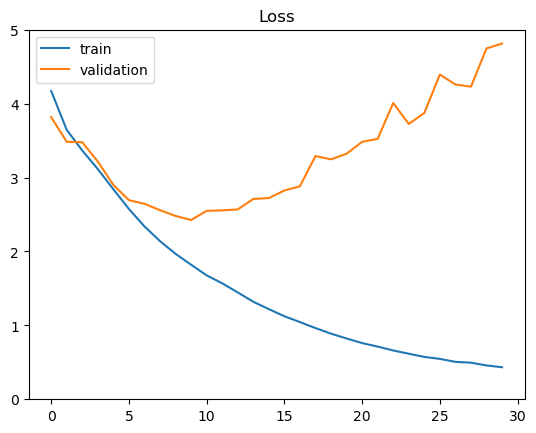

In [76]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.ylim(0, 5)
plt.legend(loc='best')
plt.title('Loss');

In [67]:
print(history.history.keys())

dict_keys(['loss', 'accuracy', 'precision_5', 'recall_5', 'val_loss', 'val_accuracy', 'val_precision_5', 'val_recall_5'])


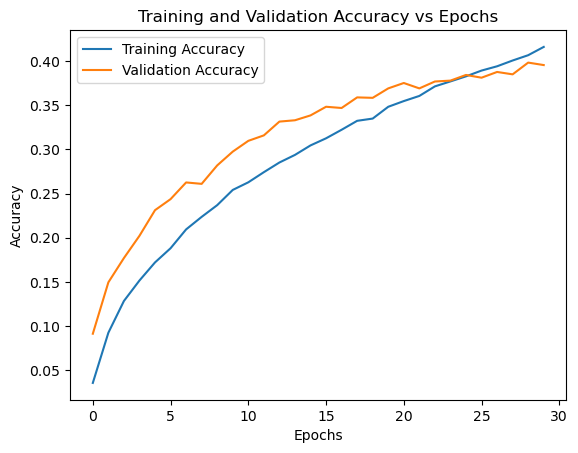

In [68]:

# Plot the training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

# Add labels and title
plt.title('Training and Validation Accuracy vs Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Show the plot
plt.show()

313/313 [==============================] - 1s 3ms/step


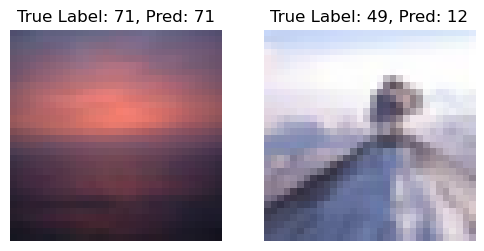

Classification probabilities for correctly classified image: [1.18423521e-03 6.31570164e-03 2.01983153e-06 4.57111446e-06
 3.92515449e-06 3.25041998e-04 2.47940299e-08 3.26471167e-07
 1.89374020e-07 5.44071700e-05 4.34312591e-04 6.79759933e-06
 1.58488823e-04 2.13836884e-07 9.14420806e-09 7.83850010e-06
 2.05998658e-05 2.35739808e-05 6.48219939e-05 3.71107853e-05
 1.48528090e-06 6.07319066e-08 4.89708873e-06 8.59465897e-02
 5.18451714e-07 2.14548782e-03 1.03605294e-06 1.97749364e-06
 4.84894612e-04 1.02783440e-06 1.44671833e-06 1.81291341e-06
 1.28601780e-04 1.17555470e-03 1.37380503e-05 3.96131725e-07
 1.06927022e-04 3.64114476e-06 2.44236753e-06 1.30477247e-05
 1.73071271e-03 2.74705735e-06 4.94636758e-08 1.63490768e-08
 1.34839265e-05 6.35361903e-06 8.96499569e-06 3.10706564e-05
 6.91648128e-10 7.78253376e-02 6.59477962e-07 5.62014102e-05
 6.64360611e-09 3.53398027e-05 4.21862496e-04 1.34332540e-05
 4.21908317e-06 9.96802482e-05 5.09067831e-07 7.08229436e-07
 2.27994308e-01 6.932105

In [69]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Get predictions on the test set
y_pred = model.predict(x_test)

# Convert the predictions to class labels
y_pred_classes = np.argmax(y_pred, axis=-1)
y_true = np.argmax(y_test, axis=-1)

# Correctly classified image (first correct prediction in the test set)
correct_index = np.where(y_pred_classes == y_true)[0][0]

# Incorrectly classified image (first incorrect prediction in the test set)
incorrect_index = np.where(y_pred_classes != y_true)[0][0]

# Plot correctly classified image
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(x_test[correct_index])
plt.title(f"True Label: {y_true[correct_index]}, Pred: {y_pred_classes[correct_index]}")
plt.axis('off')

# Plot incorrectly classified image
plt.subplot(1, 2, 2)
plt.imshow(x_test[incorrect_index])
plt.title(f"True Label: {y_true[incorrect_index]}, Pred: {y_pred_classes[incorrect_index]}")
plt.axis('off')

plt.show()

# Print the probabilities for both images
print(f"Classification probabilities for correctly classified image: {y_pred[correct_index]}")
print(f"Classification probabilities for incorrectly classified image: {y_pred[incorrect_index]}")


In [ ]:
# Training vs Validation Accuracy:
# If the training accuracy is much higher than the validation accuracy, it suggests that the model
# is overfitting — learning well on the training data but failing to generalize to new data.
# If the two curves are close, it means the model is generalizing well.
# The gap between training and validation accuracy can also help determine whether the model
# is underfitting (if both accuracies are low) or overfitting (if the gap is large).
# Correct and Incorrect Predictions:
# For the correctly classified image, you should see that the model has a very high classification probability for the true class,
# with much lower probabilities for all other classes.
# For the incorrectly classified image, the probabilities should show that the model was most confident about an incorrect class.
# It’s possible that the model was confused by visual features that resemble the true class but were more similar to the incorrect class.
# Do the Results Make Sense?
# Yes, if the model is underperforming (low accuracy, especially for validation), it might indicate a need for model adjustments,
# better data augmentation, or a more complex architecture. However, if the model has very high training accuracy and much lower validation accuracy, it strongly suggests overfitting.
# If the model is making misclassifications with high confidence, it indicates that the model might need to be regularized or
# that additional data is required to improve generalization.
# What Do the Classification Probabilities Indicate?
# The classification probabilities provide insight into how sure the model is about its predictions.
# A high probability for the correct class indicates the model is confident in its decision,
# while a high probability for an incorrect class shows a potential issue with model generalization or data representation.

## Task 4: Model Enhancement (Complete or Incomplete)
### Task 4a: Implementation of at least one advanced technique

- Now it's time to improve your model. Implement at least one technique to improve your model's performance. You can use any of the techniques we have covered in class, or you can use a technique that we haven't covered. If you need inspiration, you can refer to the [Keras documentation](https://keras.io/).
- Explain the technique you used and why you chose it.
- If you used a technique that requires tuning, explain how you selected the values for the hyperparameters.

In [71]:
# Your Code Here

from tensorflow.keras.layers import BatchNormalization, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.models import Sequential

# Define the model
model_new = Sequential([
    # First convolutional block
    Conv2D(32, (3, 3), activation=None, padding='same', input_shape=(32, 32, 3)),
    BatchNormalization(),  # Adding BatchNormalization layer
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),

    # Second convolutional block
    Conv2D(64, (3, 3), activation=None, padding='same'),
    BatchNormalization(),  # Adding BatchNormalization layer
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),

    # Third convolutional block
    Conv2D(128, (3, 3), activation=None, padding='same'),
    BatchNormalization(),  # Adding BatchNormalization layer
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),

    # Flatten and fully connected layers
    Flatten(),
    Dense(128, activation='relu'),
    Dense(100, activation='softmax')  # 100 output units for CIFAR-100 classes
])


In [ ]:
# Why Choose Batch Normalization?
# No tuning: The technique works well across a wide range of network architectures and doesn’t require additional tuning (apart from placing the layers correctly).
# Increased convergence speed: Batch Normalization often accelerates the training process, 
# allowing the model to converge faster, especially when combined with optimization algorithms like Adam.
# Improved generalization: It can help the model generalize better.

### Task 4b: Evaluation of the enhanced model

- Re-train your model using the same number of epochs as before.
- Compare the accuracy and other selected metric on the test set to the results you obtained before.
- As before, plot the training accuracy and validation accuracy with respect to epochs, and select an image that the model correctly classified in the test set, and an image that the model incorrectly classified in the test set. Plot the images and report the model's classification probabilities for each.

In [72]:
# Your Code Here
# Compile the model
model_new.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])

# Train the model
history = model_new.fit(x_train, y_train, epochs=30, batch_size=32, validation_data=(x_val, y_val))

Epoch 1/30
1250/1250 [==============================] - 36s 28ms/step - loss: 4.1719 - accuracy: 0.0617 - precision_6: 0.5122 - recall_6: 0.0010 - val_loss: 3.8178 - val_accuracy: 0.1030 - val_precision_6: 0.5878 - val_recall_6: 0.0087
Epoch 2/30
1250/1250 [==============================] - 35s 28ms/step - loss: 3.6454 - accuracy: 0.1204 - precision_6: 0.6167 - recall_6: 0.0098 - val_loss: 3.4834 - val_accuracy: 0.1327 - val_precision_6: 0.6950 - val_recall_6: 0.0098
Epoch 3/30
1250/1250 [==============================] - 35s 28ms/step - loss: 3.3658 - accuracy: 0.1589 - precision_6: 0.6667 - recall_6: 0.0219 - val_loss: 3.4775 - val_accuracy: 0.1558 - val_precision_6: 0.6032 - val_recall_6: 0.0336
Epoch 4/30
1250/1250 [==============================] - 36s 29ms/step - loss: 3.1140 - accuracy: 0.2009 - precision_6: 0.6908 - recall_6: 0.0444 - val_loss: 3.2165 - val_accuracy: 0.1971 - val_precision_6: 0.6490 - val_recall_6: 0.0551
Epoch 5/30
1250/1250 [==============================] - 

313/313 [==============================] - 2s 7ms/step


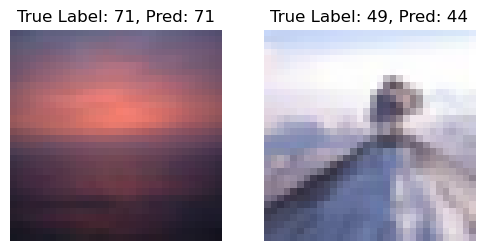

Classification probabilities for correctly classified image: [4.06637099e-07 2.05130114e-11 1.87840635e-14 3.29805239e-10
 1.65728348e-10 3.33912537e-10 1.03997398e-17 2.67941141e-10
 6.73075520e-19 2.18374867e-11 5.22447120e-11 4.79827156e-14
 1.03768868e-11 9.21617383e-14 6.33215289e-20 1.49615667e-11
 2.82139367e-10 3.73578612e-10 8.36780956e-08 4.08430338e-11
 1.11379261e-09 9.81574949e-18 1.83190119e-09 3.01100444e-02
 1.09080922e-09 2.93795019e-05 1.02604129e-15 1.48745880e-14
 1.53717349e-12 1.29489084e-13 8.77154562e-08 1.14942704e-08
 8.96426064e-15 1.25333900e-05 1.67797849e-16 6.51696615e-16
 1.82718727e-12 1.25835613e-14 1.24194165e-14 1.01820888e-06
 3.73161157e-07 2.70068944e-17 1.04031389e-12 2.52184389e-19
 1.80631632e-09 4.72619936e-13 3.87590106e-13 4.06522482e-10
 8.45205007e-20 1.46892695e-02 5.74173556e-11 1.19586320e-11
 8.00827493e-08 1.16954038e-12 1.78451261e-13 2.45811288e-11
 7.90343763e-11 2.16717096e-12 1.39738417e-17 2.15559081e-12
 3.00955027e-02 8.723731

In [73]:

# Get predictions on the test set
y_pred = model_new.predict(x_test)

# Convert the predictions to class labels
y_pred_classes = np.argmax(y_pred, axis=-1)
y_true = np.argmax(y_test, axis=-1)

# Correctly classified image (first correct prediction in the test set)
correct_index = np.where(y_pred_classes == y_true)[0][0]

# Incorrectly classified image (first incorrect prediction in the test set)
incorrect_index = np.where(y_pred_classes != y_true)[0][0]

# Plot correctly classified image
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(x_test[correct_index])
plt.title(f"True Label: {y_true[correct_index]}, Pred: {y_pred_classes[correct_index]}")
plt.axis('off')

# Plot incorrectly classified image
plt.subplot(1, 2, 2)
plt.imshow(x_test[incorrect_index])
plt.title(f"True Label: {y_true[incorrect_index]}, Pred: {y_pred_classes[incorrect_index]}")
plt.axis('off')

plt.show()

# Print the probabilities for both images
print(f"Classification probabilities for correctly classified image: {y_pred[correct_index]}")
print(f"Classification probabilities for incorrectly classified image: {y_pred[incorrect_index]}")


### Task 4c: Discussion of the results

- Briefly discuss the results.
- Did the model's performance improve?
- Why do you think this is?
- Do you think there is room for further improvement? Why or why not?
- What other techniques might you try in the future?
- Your answer should be no more than 200 words.

# Your answer here

In [ ]:
# in an ideal world we expect the model's performance to improve after enhancing it, while due to lack of proccess power on my
# I couldn't train a much better model.
# the model's performance is almost the same. Incrasing the number of epochs and lowering the training rate can help obtain a better
# performance.
# There are other techniques out there and a more complex CNN can be built to obtain better performance and accuracy.

## Criteria

|Criteria|Complete|Incomplete|
|----|----|----|
|Task 1|The task has been completed successfully and there are no errors.|The task is still incomplete and there is at least one error.|
|Task 2|The task has been completed successfully and there are no errors.|The task is still incomplete and there is at least one error.|
|Task 3|The task has been completed successfully and there are no errors.|The task is still incomplete and there is at least one error.|
|Task 4|The task has been completed successfully and there are no errors.|The task is still incomplete and there is at least one error.|

## Submission Information

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.

### Submission Parameters:
* Submission Due Date: `HH:MM AM/PM - DD/MM/YYYY`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb) should be populated and should be the only change in your pull request.
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
    * Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.

Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.

If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-3-help`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.